In [1]:
import os, json, shutil, subprocess, time, textwrap, zipfile, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

BASE = Path("/content/Conveyor_Belt_MLOps")
DATA = BASE / "data"
MODELS = BASE / "models"
REPORTS = BASE / "reports"
for folder in [DATA, MODELS, REPORTS]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project folder:", BASE)

Project folder: /content/Conveyor_Belt_MLOps


In [2]:
from google.colab import files

uploaded = files.upload()  # Select conveyor_shift_dataset_v1_v2.csv

csv_files = [name for name in uploaded.keys() if name.lower().endswith(".csv")]
if csv_files:
    source_path = Path(csv_files[0])
    raw = pd.read_csv(source_path)
    print("Loaded:", source_path.name)
else:
    raw = None
    print("No CSV uploaded. A synthetic dataset will be generated in the next cell.")

Saving conveyor_shift_dataset_v1_v2.csv to conveyor_shift_dataset_v1_v2.csv
Loaded: conveyor_shift_dataset_v1_v2.csv


In [4]:
sensor_cols = [
    "motor_current_A", "rated_motor_current_A", "vibration_mm_s",
    "belt_age_months", "parcels_per_minute", "dust_accumulation_index",
    "days_since_maintenance", "humidity_percent"
]
print("Missing values before cleaning:")
display(dataset[sensor_cols + ["next_shift_jam"]].isna().sum())

dataset = dataset.drop_duplicates().dropna(subset=sensor_cols + ["next_shift_jam"]).copy()
dataset = dataset[(dataset["rated_motor_current_A"] > 0)].copy()

# Physical/range validation for the synthetic demonstration.
dataset["dust_accumulation_index"] = dataset["dust_accumulation_index"].clip(0, 100)
dataset["humidity_percent"] = dataset["humidity_percent"].clip(0, 100)
dataset["next_shift_jam"] = dataset["next_shift_jam"].astype(int)

print("Cleaned shape:", dataset.shape)
print("Target distribution:")
display(dataset["next_shift_jam"].value_counts().rename(index={0:"Normal",1:"Jam"}))

Missing values before cleaning:


,0
motor_current_A,0
rated_motor_current_A,0
vibration_mm_s,0
belt_age_months,0
parcels_per_minute,0
dust_accumulation_index,0
days_since_maintenance,0
humidity_percent,0
next_shift_jam,0


Cleaned shape: (500, 11)
Target distribution:


,count
next_shift_jam,
Normal,397
Jam,103


In [6]:
dataset["motor_load_ratio"] = (
    dataset["motor_current_A"] /
    dataset["rated_motor_current_A"].clip(lower=0.01)
)

dataset["belt_wear_pressure_index"] = (
    (dataset["belt_age_months"] / 60.0) *
    (1.0 + dataset["dust_accumulation_index"] / 100.0)
)

FEATURES = [
    "motor_current_A", "rated_motor_current_A", "vibration_mm_s",
    "belt_age_months", "parcels_per_minute", "dust_accumulation_index",
    "days_since_maintenance", "humidity_percent",
    "motor_load_ratio", "belt_wear_pressure_index"
]
TARGET = "next_shift_jam"

feature_store = dataset[["record_id", "version"] + FEATURES + [TARGET]].copy()
feature_store.to_csv(DATA / "feature_store.csv", index=False)
display(feature_store.head())
print("Feature store saved:", DATA / "feature_store.csv")

,record_id,version,motor_current_A,rated_motor_current_A,vibration_mm_s,belt_age_months,parcels_per_minute,dust_accumulation_index,days_since_maintenance,humidity_percent,motor_load_ratio,belt_wear_pressure_index,next_shift_jam
0,V1-001,V1,16.55,18,2.00,1,33.40,32.5,23.0,43.3,0.919444,0.022083,0
1,V1-002,V1,13.17,15,3.87,11,20.66,19.9,38.0,40.4,0.878000,0.219817,0
2,V1-003,V1,22.21,20,4.08,1,42.02,43.6,39.0,34.1,1.110500,0.023933,0
3,V1-004,V1,9.42,10,2.54,22,49.41,28.0,5.0,41.6,0.942000,0.469333,0
4,V1-005,V1,16.44,18,4.06,32,20.65,11.5,43.0,43.5,0.913333,0.594667,1


Feature store saved: /content/Conveyor_Belt_MLOps/data/feature_store.csv


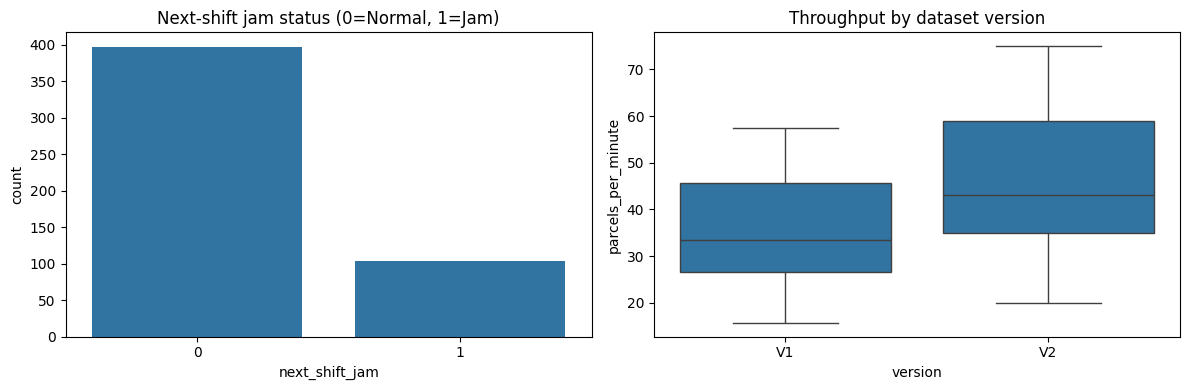

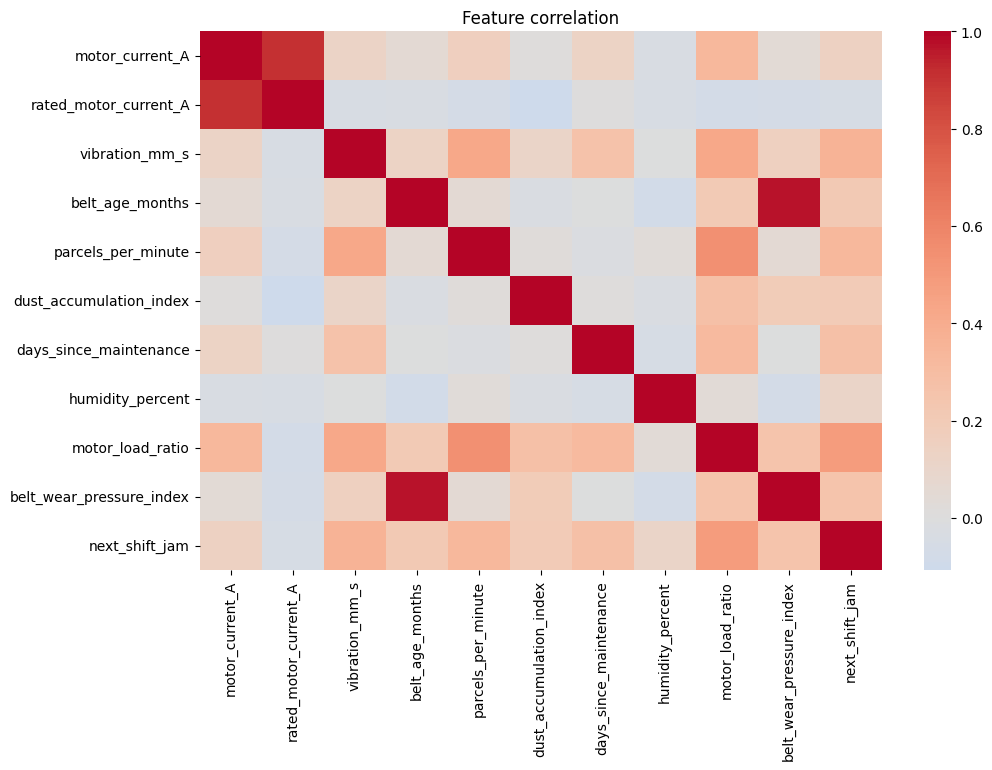

,average_parcels_per_minute
version,
V1,35.84536
V2,46.57200


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
sns.countplot(data=dataset, x="next_shift_jam", ax=axes[0])
axes[0].set_title("Next-shift jam status (0=Normal, 1=Jam)")
sns.boxplot(data=dataset, x="version", y="parcels_per_minute", ax=axes[1])
axes[1].set_title("Throughput by dataset version")
plt.tight_layout()
plt.show()

plt.figure(figsize=(11,7))
sns.heatmap(feature_store[FEATURES + [TARGET]].corr(), cmap="coolwarm", center=0)
plt.title("Feature correlation")
plt.show()

throughput = dataset.groupby("version")["parcels_per_minute"].mean()
display(throughput.to_frame("average_parcels_per_minute"))

In [8]:
X = feature_store[FEATURES].astype(float)
y = feature_store[TARGET].astype(int)

if y.nunique() < 2:
    raise ValueError("The target column must contain both classes (0 and 1) to train classifiers.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1500, class_weight="balanced", random_state=42))
])
lr_model.fit(X_train, y_train)

rf_model = RandomForestClassifier(
    n_estimators=200, max_depth=8, min_samples_leaf=2,
    class_weight="balanced", random_state=42
)
rf_model.fit(X_train, y_train)

print("Both models trained.")

Both models trained.


,Model,Accuracy,Recall,F1 Score
0,Logistic Regression,0.84,0.761905,0.666667
1,Random Forest,0.84,0.428571,0.529412


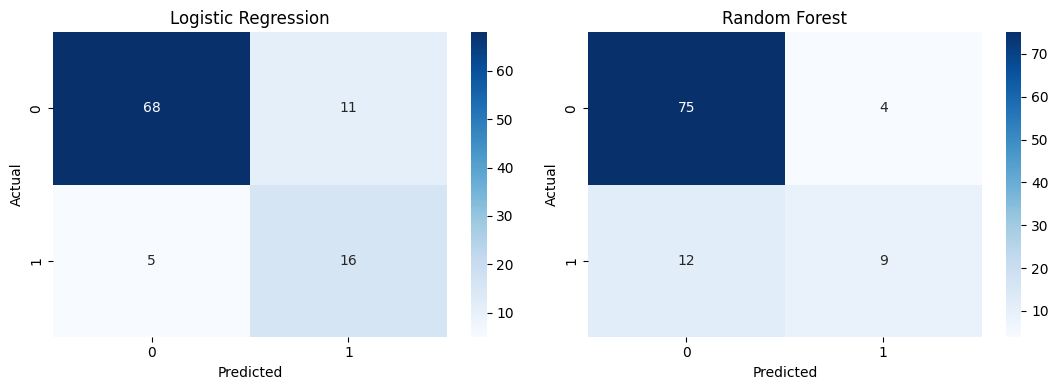


 Logistic Regression
              precision    recall  f1-score   support

           0       0.93      0.86      0.89        79
           1       0.59      0.76      0.67        21

    accuracy                           0.84       100
   macro avg       0.76      0.81      0.78       100
weighted avg       0.86      0.84      0.85       100


 Random Forest
              precision    recall  f1-score   support

           0       0.86      0.95      0.90        79
           1       0.69      0.43      0.53        21

    accuracy                           0.84       100
   macro avg       0.78      0.69      0.72       100
weighted avg       0.83      0.84      0.83       100



In [9]:
models = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model
}
predictions = {}
rows = []

for name, model in models.items():
    pred = model.predict(X_test)
    predictions[name] = pred
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1 Score": f1_score(y_test, pred, zero_division=0)
    })

comparison = pd.DataFrame(rows).sort_values(
    ["Recall", "F1 Score"], ascending=False
).reset_index(drop=True)
display(comparison)

fig, axes = plt.subplots(1, 2, figsize=(11,4))
for ax, name in zip(axes, models.keys()):
    sns.heatmap(confusion_matrix(y_test, predictions[name]), annot=True, fmt="d",
                cmap="Blues", ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

for name in models:
    print("\n", name)
    print(classification_report(y_test, predictions[name], zero_division=0))

In [10]:
# Recall is prioritized because failing to flag a jam is operationally costly.
best_name = comparison.iloc[0]["Model"]
best_model = models[best_name]
best_model_path = MODELS / "best_model.pkl"
joblib.dump(best_model, best_model_path)

with open(MODELS / "model_metadata.json", "w") as f:
    json.dump({"selected_model": best_name, "features": FEATURES}, f, indent=2)

print("Selected model:", best_name)
print("Saved:", best_model_path)

Selected model: Logistic Regression
Saved: /content/Conveyor_Belt_MLOps/models/best_model.pkl


In [ ]:
import mlflow
import mlflow.sklearn
from mlflow.tracking import MlflowClient

mlflow.set_tracking_uri(
    f"sqlite:///{BASE / 'mlflow.db'}"
)

mlflow.set_experiment("Conveyor_Belt_Jam_Prediction")

registered_model_name = "ConveyorJamPrediction"

with mlflow.start_run(run_name=best_name) as run:

    mlflow.log_param("selected_model", best_name)
    mlflow.log_param("dataset_records", len(feature_store))
    mlflow.log_param("dataset_versions", "V1,V2")
    mlflow.log_param("test_size", 0.20)

    best_pred = best_model.predict(X_test)

    mlflow.log_metric(
        "accuracy",
        accuracy_score(y_test, best_pred)
    )

    mlflow.log_metric(
        "recall",
        recall_score(y_test, best_pred, zero_division=0)
    )

    mlflow.log_metric(
        "f1_score",
        f1_score(y_test, best_pred, zero_division=0)
    )

    mlflow.log_artifact(
        str(DATA / "feature_store.csv")
    )

    mlflow.sklearn.log_model(
        sk_model=best_model,
        name="conveyor_model",
        registered_model_name=registered_model_name
    )

    run_id = run.info.run_id

print("MLflow Run ID:", run_id)
print("Registered Model:", registered_model_name)

client = MlflowClient()

for model in client.search_registered_models():

    print("Model Name:", model.name)

    for version in model.latest_versions:
        print("Version:", version.version)
        print("Status:", version.status)

In [12]:
app_code = r'''
from pathlib import Path
import joblib
import pandas as pd
from fastapi import FastAPI
from pydantic import BaseModel, Field

BASE = Path(__file__).resolve().parent
MODEL_PATH = BASE / "models" / "best_model.pkl"
model = joblib.load(MODEL_PATH)

FEATURES = [
    "motor_current_A", "rated_motor_current_A", "vibration_mm_s",
    "belt_age_months", "parcels_per_minute", "dust_accumulation_index",
    "days_since_maintenance", "humidity_percent",
    "motor_load_ratio", "belt_wear_pressure_index"
]

app = FastAPI(title="Conveyor Belt Jam Prediction API", version="1.0")

class ConveyorInput(BaseModel):
    motor_current_A: float = Field(gt=0)
    rated_motor_current_A: float = Field(gt=0)
    vibration_mm_s: float = Field(ge=0)
    belt_age_months: float = Field(ge=0)
    parcels_per_minute: float = Field(ge=0)
    dust_accumulation_index: float = Field(ge=0, le=100)
    days_since_maintenance: float = Field(ge=0)
    humidity_percent: float = Field(ge=0, le=100)

@app.get("/health")
def health():
    return {"status": "healthy", "model": "ConveyorJamPrediction"}

@app.post("/predict")
def predict(data: ConveyorInput):
    row = data.model_dump()
    row["motor_load_ratio"] = row["motor_current_A"] / row["rated_motor_current_A"]
    row["belt_wear_pressure_index"] = (
        row["belt_age_months"] / 60.0 *
        (1.0 + row["dust_accumulation_index"] / 100.0)
    )
    X_input = pd.DataFrame([[row[c] for c in FEATURES]], columns=FEATURES)
    prediction = int(model.predict(X_input)[0])
    return {
        "prediction": "Jam Risk" if prediction == 1 else "Normal Operation",
        "jam_status": prediction,
        "motor_load_ratio": round(row["motor_load_ratio"], 3),
        "belt_wear_pressure_index": round(row["belt_wear_pressure_index"], 3)
    }
'''
(BASE / "app.py").write_text(app_code)
print("Created", BASE / "app.py")

Created /content/Conveyor_Belt_MLOps/app.py


In [13]:
# Import the same model and construct the prediction function for an in-notebook test.
from fastapi.testclient import TestClient
import importlib.util

spec = importlib.util.spec_from_file_location("conveyor_app", BASE / "app.py")
conveyor_app = importlib.util.module_from_spec(spec)
spec.loader.exec_module(conveyor_app)
client = TestClient(conveyor_app.app)

health_response = client.get("/health")
assert health_response.status_code == 200
print("Health:", health_response.json())

sample = {
    "motor_current_A": 17.5,
    "rated_motor_current_A": 18.0,
    "vibration_mm_s": 8.5,
    "belt_age_months": 48,
    "parcels_per_minute": 120,
    "dust_accumulation_index": 85,
    "days_since_maintenance": 75,
    "humidity_percent": 80
}
prediction_response = client.post("/predict", json=sample)
assert prediction_response.status_code == 200
assert prediction_response.json()["prediction"] in ["Jam Risk", "Normal Operation"]
print("Prediction:", prediction_response.json())

invalid = dict(sample)
invalid["motor_current_A"] = -2
invalid_response = client.post("/predict", json=invalid)
assert invalid_response.status_code == 422
print("Invalid sensor input correctly rejected:", invalid_response.status_code)
print("All API checks passed.")

Health: {'status': 'healthy', 'model': 'ConveyorJamPrediction'}
Prediction: {'prediction': 'Jam Risk', 'jam_status': 1, 'motor_load_ratio': 0.972, 'belt_wear_pressure_index': 1.48}
Invalid sensor input correctly rejected: 422
All API checks passed.


In [14]:
test_code = r'''
from fastapi.testclient import TestClient
from app import app

client = TestClient(app)

def test_health():
    response = client.get("/health")
    assert response.status_code == 200
    assert response.json()["status"] == "healthy"

def test_prediction():
    sample = {
        "motor_current_A": 17.5,
        "rated_motor_current_A": 18.0,
        "vibration_mm_s": 8.5,
        "belt_age_months": 48,
        "parcels_per_minute": 120,
        "dust_accumulation_index": 85,
        "days_since_maintenance": 75,
        "humidity_percent": 80
    }
    response = client.post("/predict", json=sample)
    assert response.status_code == 200
    assert response.json()["prediction"] in ["Jam Risk", "Normal Operation"]

def test_invalid_input():
    sample = {
        "motor_current_A": -2,
        "rated_motor_current_A": 18.0,
        "vibration_mm_s": 8.5,
        "belt_age_months": 48,
        "parcels_per_minute": 120,
        "dust_accumulation_index": 85,
        "days_since_maintenance": 75,
        "humidity_percent": 80
    }
    response = client.post("/predict", json=sample)
    assert response.status_code == 422
'''
(BASE / "test_api.py").write_text(test_code)
print("Created test_api.py")

Created test_api.py


In [15]:
result = subprocess.run(
    [sys.executable, "-m", "pytest", "-v", str(BASE / "test_api.py")],
    cwd=str(BASE), capture_output=True, text=True
)
print(result.stdout)
print(result.stderr)
print("Pytest exit code:", result.returncode)
assert result.returncode == 0, "One or more tests failed."

============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/Conveyor_Belt_MLOps
plugins: platformdirs-4.14.3, langsmith-0.14.17, anyio-4.16.0, typeguard-4.6.0
collecting ... collected 3 items

test_api.py::test_health PASSED                                          [ 33%]
test_api.py::test_prediction PASSED                                      [ 66%]
test_api.py::test_invalid_input PASSED                                   [100%]

============================== 3 passed in 1.71s ===============================


Pytest exit code: 0


In [16]:
workflow_dir = BASE / ".github" / "workflows"
workflow_dir.mkdir(parents=True, exist_ok=True)

requirements = '''
pandas
numpy
scikit-learn
mlflow
fastapi
uvicorn
joblib
pydantic
pytest
httpx
matplotlib
seaborn
reportlab
'''

(BASE / "requirements.txt").write_text(requirements.strip() + "\n")

ci_yaml = '''
name: Conveyor MLOps CI

on:
  push:
    branches: [main]
  pull_request:
    branches: [main]

jobs:
  test:
    runs-on: ubuntu-latest
    steps:
      - name: Checkout repository
        uses: actions/checkout@v4

      - name: Set up Python
        uses: actions/setup-python@v5
        with:
          python-version: "3.11"

      - name: Install dependencies
        run: |
          python -m pip install --upgrade pip
          pip install -r requirements.txt

      - name: Run API tests
        run: pytest -v test_api.py
'''
(workflow_dir / "ci.yml").write_text(textwrap.dedent(ci_yaml).strip() + "\n")
print("Created requirements.txt and .github/workflows/ci.yml")

Created requirements.txt and .github/workflows/ci.yml


In [17]:
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.lib.pagesizes import A4

pdf_path = REPORTS / "Conveyor_Belt_MLOps_Report.pdf"
styles = getSampleStyleSheet()
story = [
    Paragraph("Conveyor Belt Jamming Prediction Using MLOps", styles["Title"]),
    Spacer(1, 12),
    Paragraph("Problem Statement", styles["Heading2"]),
    Paragraph("Predict whether a conveyor belt is likely to jam during its next operating shift using sensor measurements and maintenance records.", styles["BodyText"]),
    Spacer(1, 8),
    Paragraph("Workflow Architecture", styles["Heading2"]),
    Paragraph("CSV dataset versions → preprocessing → engineered feature store → Logistic Regression and Random Forest → evaluation → MLflow registry → FastAPI serving → automated tests and GitHub Actions.", styles["BodyText"]),
    Spacer(1, 8),
    Paragraph("Dataset Versions", styles["Heading2"]),
    Paragraph(f"Combined records: {len(dataset)}. V1 records: {int((dataset.version=='V1').sum())}. V2 records: {int((dataset.version=='V2').sum())}. V2 is intended to represent increased festival-period throughput and operating stress.", styles["BodyText"]),
    Spacer(1, 8),
    Paragraph("Feature Engineering", styles["Heading2"]),
    Paragraph("motor_load_ratio = motor_current_A / rated_motor_current_A. belt_wear_pressure_index = (belt_age_months / 60) × (1 + dust_accumulation_index / 100).", styles["BodyText"]),
    Spacer(1, 8),
    Paragraph("Model Comparison", styles["Heading2"])
]

table_data = [["Model", "Accuracy", "Recall", "F1-score"]]
for _, row in comparison.iterrows():
    table_data.append([row["Model"], f'{row["Accuracy"]:.4f}', f'{row["Recall"]:.4f}', f'{row["F1 Score"]:.4f}'])
tbl = Table(table_data, repeatRows=1)
tbl.setStyle(TableStyle([
    ("BACKGROUND", (0,0), (-1,0), colors.lightblue),
    ("GRID", (0,0), (-1,-1), 0.5, colors.grey),
    ("PADDING", (0,0), (-1,-1), 6)
]))
story += [tbl, Spacer(1, 8),
    Paragraph("Model Registry and Serving", styles["Heading2"]),
    Paragraph(f"Selected model: {best_name}. Model tracking and registration are performed with MLflow under the registered name ConveyorJamPrediction. FastAPI exposes GET /health and POST /predict; prediction labels are Jam Risk or Normal Operation.", styles["BodyText"]),
    Spacer(1, 8),
    Paragraph("CI/CD and Testing", styles["Heading2"]),
    Paragraph("GitHub Actions installs requirements and runs pytest for health, prediction and invalid-input validation. Run the workflow after pushing the project to GitHub and capture the successful Actions run as submission evidence.", styles["BodyText"]),
    Spacer(1, 8),
    Paragraph("Limitations", styles["Heading2"]),
    Paragraph("Synthetic data is suitable for demonstrating the workflow only. The reported scores are test-split results on this dataset and do not establish real-world industrial performance. A production system needs validated sensor data, temporal validation, monitoring, retraining and human maintenance procedures.", styles["BodyText"])
]
SimpleDocTemplate(str(pdf_path), pagesize=A4).build(story)
print("PDF generated:", pdf_path)

ModuleNotFoundError: No module named 'reportlab'

In [18]:
zip_path = Path("/content/Conveyor_Belt_MLOps_Project.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for path in BASE.rglob("*"):
        if path.is_file():
            z.write(path, path.relative_to(BASE.parent))
print("Project ZIP ready:", zip_path)

from google.colab import files
files.download(str(zip_path))

Project ZIP ready: /content/Conveyor_Belt_MLOps_Project.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>